# 2.11d — ADMM pour le Lasso : consensus et proximal

[Source Python](2.11d-Optimisation-ADMM-From-Scratch.ipynb) | [Index](README.md)

**Objectifs** : dériver les mises à jour, vérifier les résidus et les tolérances, puis comparer ADMM aux descentes de coordonnées et à une référence numérique. **Prérequis** : Lasso, systèmes linéaires et proximal L1. **Durée indicative** : 90 minutes.

Le carnet prolonge [2.11](2.11-Regularisation-Sparse-LASSO.ipynb) (géométrie et coordonnées), [2.11b](2.11b-Proximal-Operators-From-Scratch.ipynb) (ISTA/FISTA) et [2.11c](2.11c-Lasso-SOTA-Comparison.ipynb), avant [2.11e](2.11e-CVXPY-Optimisation.ipynb) et [2.11f](2.11f-Comparaison-Optimisation-Convexe.ipynb). Nous minimisons `½‖Xβ−y‖²+λ‖z‖₁` sous `β=z`. MathNet calcule les algorithmes C# ; NumPy et les références réelles sklearn/CVXPY sont appelés via Python.NET.

### Configurer Python.NET

Installer NumPy, SciPy, scikit-learn, CVXPY et CLARABEL (ou SCS pour le repli) dans un CPython compatible. Définir `PYTHONNET_PYDLL` vers sa bibliothèque partagée ; vérifier que son répertoire standard et les `site-packages` contenant ces bibliothèques sont visibles du processus .NET. Selon l'installation, configurer `PYTHONHOME` vers le préfixe CPython et `PYTHONPATH` vers les `site-packages` du venv. La bibliothèque seule ne sélectionne pas nécessairement l'environnement. Vérifier les imports avant exécution ; aucun chemin propre à une machine n'est requis dans le code.

### Place dans la chaîne

Le parent 2.11 introduit la géométrie des pénalités L1 et L2, le seuillage doux et la descente de coordonnées. Il utilise aussi LassoCV pour sélectionner λ ; ici λ reste fixé pour isoler les algorithmes. Le mélange ElasticNet sort du périmètre de ce carnet. ADMM apporte une décomposition par blocs et des résidus de consensus ; les usages distribués et les grands régimes structurés ne sont pas mesurés ici.

**Navigation** : [Parent : régularisation](2.11-Regularisation-Sparse-LASSO.ipynb) | [Version Python de cette étape](2.11d-Optimisation-ADMM-From-Scratch.ipynb) | [Suivant : 2.11e](2.11e-CVXPY-Optimisation.ipynb) | [Index](README.md)


In [1]:
#r "nuget: MathNet.Numerics, 5.0.0"
#r "nuget: PythonNet, 3.0.5"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Diagnostics;
using System.Text;
using System.Text.Json;
using MathNet.Numerics.LinearAlgebra;
using Python.Runtime;
using Microsoft.DotNet.Interactive.Formatting;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
// Le pont charge le CPython configuré une seule fois ; ADMM reste calculé en C#.
if (!PythonEngine.IsInitialized)
{
    var library = Environment.GetEnvironmentVariable("PYTHONNET_PYDLL");
    if (string.IsNullOrWhiteSpace(library))
        throw new InvalidOperationException("Définir PYTHONNET_PYDLL vers CPython et installer NumPy, scikit-learn et CVXPY.");
    Runtime.PythonDLL = library;
    PythonEngine.Initialize();
    PythonEngine.BeginAllowThreads();
}
string PythonResult(string source)
{
    using (Py.GIL())
    using (var scope = Py.CreateScope())
    {
        scope.Exec(source);
        return scope.Get("result").As<string>();
    }
}
var V = Vector<double>.Build;
var Mat = Matrix<double>.Build;
Vector<double> ArrayVector(JsonElement array) => V.DenseOfEnumerable(array.EnumerateArray().Select(x => x.GetDouble()));
Matrix<double> ArrayMatrix(JsonElement array) => Mat.DenseOfRowArrays(array.EnumerateArray().Select(row => row.EnumerateArray().Select(x => x.GetDouble()).ToArray()).ToArray());
// La variable z utilise le proximal L1, qui annule exactement les petites composantes.
Vector<double> Shrink(Vector<double> x, double threshold) => x.Map(v => Math.Sign(v) * Math.Max(Math.Abs(v) - threshold, 0.0));
double Objective(Matrix<double> a, Vector<double> b, Vector<double> x, double lambda)
{
    var residual = a * x - b;
    return 0.5 * residual.DotProduct(residual) + lambda * x.L1Norm();
}
Console.WriteLine("MathNet et Python.NET initialisés ; références Python chargées au besoin.");

Installed Packages MathNet.Numerics, 5.0.0 PythonNet, 3.0.5

MathNet et Python.NET initialisés ; références Python chargées au besoin.


## 1. Données corrélées et unités de régularisation

Le générateur `default_rng(20260914)` produit `n=100`, `p=50`, `k=5`, un signal sur un support aléatoire et un bruit calibré à SNR=4. La covariance **de population** est AR(1), `Σᵢⱼ=ρ_corr^|i−j|` avec `ρ_corr=0,95`, appliquée par Cholesky. La covariance empirique de 100 observations n'est pas exactement Σ. Le conditionnement, le rang et le support sont mesurés ci-dessous.

Ne pas confondre `ρ_corr`, qui modifie les données, avec `ρ`, pénalité augmentée de l'algorithme. Le seuil brut `λmax=max|Xᵀy|` donne la solution nulle au-delà de ce seuil ; on choisit ici `λ=0,5 λmax`. La perte sklearn est divisée par n : `α=λ/n` et `αmax=λmax/n` alignent les problèmes.

In [2]:
// Le générateur NumPy reproduit le design corrélé et les mêmes références.
var input = JsonDocument.Parse(PythonResult(@"
import json, time, numpy as np, cvxpy as cp
from sklearn.linear_model import Lasso
n,p,k=100,50,5
rng=np.random.default_rng(20260914)
idx=np.arange(p); Sigma=0.95**np.abs(idx[:,None]-idx[None,:])
L=np.linalg.cholesky(Sigma); X=rng.standard_normal((n,p))@L.T
support=np.sort(rng.choice(p,size=k,replace=False)); truth=np.zeros(p); truth[support]=rng.standard_normal(k)
signal=X@truth; sigma=np.linalg.norm(signal)/np.sqrt(n)/4.0
y=signal+rng.standard_normal(n)*sigma
lam=.5*np.max(np.abs(X.T@y))
start=time.perf_counter()

# La pénalité sklearn est normalisée par le nombre de lignes.
sk=Lasso(alpha=lam/n,max_iter=2000,tol=1e-6,fit_intercept=False).fit(X,y)
sk_seconds=time.perf_counter()-start
v=cp.Variable(p); prob=cp.Problem(cp.Minimize(.5*cp.sum_squares(X@v-y)+lam*cp.norm(v,1)))
start=time.perf_counter()
try:
    prob.solve(solver=cp.CLARABEL,tol_gap_abs=1e-8,tol_gap_rel=1e-8,tol_feas=1e-8,verbose=False)
except Exception:
    prob.solve(solver=cp.SCS,eps=1e-8,verbose=False)
cvx_seconds=time.perf_counter()-start
if prob.status != 'optimal': raise RuntimeError('CVXPY: '+str(prob.status))
result=json.dumps(dict(X=X.tolist(),y=y.tolist(),truth=truth.tolist(),support=support.tolist(),lam=float(lam),sklearn=sk.coef_.tolist(),cvx=np.asarray(v.value).ravel().tolist(),objective=prob.value,solver=prob.solver_stats.solver_name,sk_seconds=sk_seconds,cvx_seconds=cvx_seconds,condition=float(np.linalg.cond(X)),rank=int(np.linalg.matrix_rank(X))))")).RootElement;
var x = ArrayMatrix(input.GetProperty("X"));
var y = ArrayVector(input.GetProperty("y"));
var truth = ArrayVector(input.GetProperty("truth"));
var lambda = input.GetProperty("lam").GetDouble();
var sklearn = ArrayVector(input.GetProperty("sklearn"));
var cvx = ArrayVector(input.GetProperty("cvx"));
var optimum = input.GetProperty("objective").GetDouble();
Console.WriteLine($"n={x.RowCount}, p={x.ColumnCount}, support={string.Join(",",input.GetProperty("support").EnumerateArray().Select(i => i.GetInt32()))}, condition={input.GetProperty("condition").GetDouble():F2}");
Console.WriteLine($"Rang numérique={input.GetProperty("rank").GetInt32()}/{x.ColumnCount} ; β vrai actif={string.Join(", ",truth.Where(v=>v!=0).Select(v=>v.ToString("F3")))}");
Console.WriteLine($"λmax={2*lambda:F4}, αmax={2*lambda/x.RowCount:F4}, λ={lambda:F4}, α={lambda/x.RowCount:F4}");
Console.WriteLine($"CVXPY {input.GetProperty("solver").GetString()}, objectif={optimum:F8}");

n=100, p=50, support=2,13,24,44,47, condition=81.83


Rang numérique=50/50 ; β vrai actif=-0.243, 1.397, -1.836, 0.863, 0.617


λmax=115.2719, αmax=1.1527, λ=57.6360, α=0.5764


CVXPY CLARABEL, objectif=158.89045512


## 2. Proximal et décomposition ADMM

Le seuillage `Sτ(v)=sign(v) max(|v|−τ,0)` s'applique coordonnée par coordonnée : les valeurs dans la zone morte s'annulent exactement ; les autres gardent leur signe. Sa forme fermée vient de la séparabilité de la norme L1 et du terme quadratique. Le petit contrôle ci-dessous teste les signes, zéro et la zone morte.

Pour `min ½‖Xβ−y‖²+λ‖z‖₁` sous `β=z`, le Lagrangien échelonné comprend `+(ρ/2)‖β−z+u‖²−(ρ/2)‖u‖²` en plus de l'objectif. Le dernier terme est constant pour les minimisations en β et z. On alterne :

1. `β ← (XᵀX+ρI)⁻¹[Xᵀy+ρ(z−u)]`, résolution par une factorisation de Cholesky réutilisée ;
2. `z ← S_{λ/ρ}(β+u)` ;
3. `u ← u+β−z`.

Le primal `r_p=‖β−z‖` et le dual `r_d=ρ‖z−z_prev‖` doivent tous deux passer sous leurs seuils : `ε_p=√p ε_abs+ε_rel max(‖β‖,‖z‖)` et `ε_d=√p ε_abs+ε_rel ρ‖u‖`, ici `ε_abs=ε_rel=10⁻⁴`. `converged` peut devenir vrai au dernier passage du budget. La matrice mesurée est de rang plein dans cette expérience : son objectif est alors strictement convexe ; la convexité seule n'assure pas l'unicité en général.

La pré-factorisation dense coûte typiquement `O(p³)` une fois pour un ρ fixé ; chaque résolution triangulaire réutilisant le facteur coûte `O(p²)`, en plus des produits nécessaires aux objectifs. Le balayage refactorise pour chaque ρ : les temps rapportés portent sur ces calculs et ce petit problème, pas sur une implémentation distribuée.

In [3]:
record AdmmResult(Vector<double> Beta, Vector<double> Z, Vector<double> U, double[] ObjectiveBeta, double[] ObjectiveZ, double[] Primal, double[] Dual, bool Converged);
AdmmResult Admm(Matrix<double> a, Vector<double> b, double lam, double rho, int maxIter = 500, double epsAbs = 1e-4, double epsRel = 1e-4)
{
    int p = a.ColumnCount;
    var xt = a.Transpose();
    // Factoriser une fois la matrice symétrique définie positive pour ce rho.
    var factor = (xt * a + rho * Mat.DenseIdentity(p)).Cholesky();
    var xty = xt * b;
    var beta = V.Dense(p);
    var z = V.Dense(p);
    var u = V.Dense(p);
    var objectivesBeta = new List<double>();
    var objectivesZ = new List<double>();
    var primal = new List<double>();
    var dual = new List<double>();
    bool converged = false;
    for (int iteration = 0; iteration < maxIter; iteration++)
    {
        var previousZ = z;
        beta = factor.Solve(xty + rho * (z - u));
        z = Shrink(beta + u, lam / rho);
        u = u + beta - z;
        double rp = (beta - z).L2Norm();
        double rd = rho * (z - previousZ).L2Norm();
        // Les critères primal et dual vérifient simultanément faisabilité et stationnarité.
        double toleranceP = Math.Sqrt(p) * epsAbs + epsRel * Math.Max(beta.L2Norm(), z.L2Norm());
        double toleranceD = Math.Sqrt(p) * epsAbs + epsRel * rho * u.L2Norm();
        objectivesBeta.Add(Objective(a, b, beta, lam));
        objectivesZ.Add(Objective(a, b, z, lam));
        primal.Add(rp);
        dual.Add(rd);
        if (rp < toleranceP && rd < toleranceD)
        {
            converged = true;
            break;
        }
    }
    return new AdmmResult(beta, z, u, objectivesBeta.ToArray(), objectivesZ.ToArray(), primal.ToArray(), dual.ToArray(), converged);
}
(Vector<double> beta, int iterations, bool converged) CoordinateDescent(Matrix<double> a, Vector<double> b, double lam, int maxIter = 2000, double tol = 1e-6)
{
    var beta = V.Dense(a.ColumnCount);
    for (int iteration = 1; iteration <= maxIter; iteration++)
    {
        var previous = beta.Clone();
        for (int j = 0; j < a.ColumnCount; j++)
        {
            var column = a.Column(j);
            // Le résidu partiel retire la contribution de la coordonnée mise à jour.
            double value = column.DotProduct(b - a * beta + column * beta[j]);
            beta[j] = Math.Sign(value) * Math.Max(Math.Abs(value) - lam, 0) / column.DotProduct(column);
        }
        if ((beta - previous).L2Norm() < tol) return (beta, iteration, true);
    }
    return (beta, maxIter, false);
}
Console.WriteLine("ADMM et descente de coordonnées C# définis.");
// Vérifier les régimes du proximal sur valeurs positives et négatives.
Console.WriteLine($"Seuillage à 0,5 : {string.Join(", ",Shrink(V.DenseOfArray(new[]{-2.5,-.3,0,.3,2.5}),.5).Select(v=>v.ToString("F1")))}");

ADMM et descente de coordonnées C# définis.


Seuillage à 0,5 : -2.0, -0.0, 0.0, 0.0, 2.0


## 3. Comparer les quatre méthodes

À ρ=20, les sorties comparent ADMM à la descente de coordonnées écrite ici, à sklearn Lasso et à CVXPY. La coordonnée `j` emploie `Sλ(X_jᵀ(y−X_{−j}β_{−j}))/(X_jᵀX_j)`. On affiche pour ADMM les normes L1 de β et z et les résidus avec leurs tolérances ; le support est calculé sur z, qui porte L1.

La ligne CVXPY est une référence numérique sous tolérances, non un optimum exact symbolique. β et z sont évalués séparément ; mélanger la perte en β et la pénalité en z sur un couple non consensuel ne donnerait pas nécessairement une borne de l'objectif non scindé.

In [4]:
// Mesurer chaque moteur séparément sur les mêmes données et la même pénalisation.
var watch = Stopwatch.StartNew();
var admm = Admm(x, y, lambda, 20.0);
watch.Stop(); double admmSeconds = watch.Elapsed.TotalSeconds;
watch.Restart();
var cd = CoordinateDescent(x, y, lambda);
watch.Stop(); double cdSeconds = watch.Elapsed.TotalSeconds;
void Report(string name, Vector<double> value, int iterations, bool converged = true)
{
    // Évaluer le support sur z, qui porte le seuillage L1.
    var active = Enumerable.Range(0,value.Count).Where(i => Math.Abs(value[i]) > 1e-6).ToHashSet();
    var actual = Enumerable.Range(0,value.Count).Where(i => truth[i] != 0).ToHashSet();
    int tp = active.Intersect(actual).Count();
    double precision = tp / (double)Math.Max(active.Count, 1);
    double recall = tp / (double)actual.Count;
    double f1 = precision + recall == 0 ? 0 : 2 * precision * recall / (precision + recall);
    Console.WriteLine($"{name,-12} écart={(value-cvx).L2Norm():E3}, support={active.Count}, FP={active.Count-tp}, précision={precision:P1}, rappel={recall:P1}, F1={f1:P1}, it={(iterations > 0 ? iterations.ToString() : "non mesurées")}, convergé={(iterations > 0 ? converged.ToString() : "non mesuré")}");
}
Report("ADMM z", admm.Z, admm.Primal.Length, admm.Converged);
Report("Coordonnée", cd.beta, cd.iterations, cd.converged);
Report("sklearn", sklearn, 0);
Console.WriteLine($"Temps (s) : ADMM={admmSeconds:F4}, CD={cdSeconds:F4}, sklearn={input.GetProperty("sk_seconds").GetDouble():F4}, CVXPY={input.GetProperty("cvx_seconds").GetDouble():F4}");
Console.WriteLine($"ADMM β dense : {admm.Beta.Count(v => Math.Abs(v)>1e-6)} composantes ; résidu primal={admm.Primal.Last():E3}");
// Les résidus sont comparés à leurs seuils respectifs à l'arrêt.
double tolP=Math.Sqrt(x.ColumnCount)*1e-4+1e-4*Math.Max(admm.Beta.L2Norm(),admm.Z.L2Norm());
double tolD=Math.Sqrt(x.ColumnCount)*1e-4+1e-4*20*admm.U.L2Norm();
Console.WriteLine($"||β||₁={admm.Beta.L1Norm():F4}, ||z||₁={admm.Z.L1Norm():F4}, primal={admm.Primal.Last():E3}/{tolP:E3}, dual={admm.Dual.Last():E3}/{tolD:E3}");

ADMM z       écart=2.078E-003, support=2, FP=0, précision=100.0 %, rappel=40.0 %, F1=57.1 %, it=178, convergé=True


Coordonnée   écart=1.004E-007, support=2, FP=0, précision=100.0 %, rappel=40.0 %, F1=57.1 %, it=14, convergé=True


sklearn      écart=6.565E-008, support=2, FP=0, précision=100.0 %, rappel=40.0 %, F1=57.1 %, it=non mesurées, convergé=non mesuré


Temps (s) : ADMM=0.1273, CD=0.1215, sklearn=0.0011, CVXPY=0.0174


ADMM β dense : 48 composantes ; résidu primal=7.613E-004


||β||₁=0.8514, ||z||₁=0.8477, primal=7.613E-004/7.729E-004, dual=9.614E-004/2.403E-002


### Exercice 1 — Trajectoires de convergence

Pour `ρ={0,01, 0,1, 1, 10, 100}`, λ fixé et 500 itérations au plus, exécuter ADMM et conserver β, z, les objectifs `f(β), f(z)`, les résidus et statuts. Tracer ces deux objectifs avec la référence numérique, les résidus en log et les itérations selon ρ. Quel ρ est le plus rapide ? Est-ce celui qui équilibre les résidus ? Le garde compare les champs numériques sur plusieurs problèmes ; les tracés et l'argumentation restent à examiner.

In [5]:
AdmmResult[] ExerciceTrajectoires(Matrix<double> matrix, Vector<double> target, double lam, double[] rhos)
{
    // TODO : calculer les résultats ADMM par rho et produire les tracés demandés.
    return null;
}
bool ResultatCoherent(AdmmResult actual, AdmmResult expected)
{
    // Contrôler tous les champs utilisés par les courbes, sans assimiler l'argumentation au test numérique.
    if(actual==null || actual.Beta==null || actual.Z==null || actual.U==null ||
       actual.ObjectiveBeta==null || actual.ObjectiveZ==null || actual.Primal==null || actual.Dual==null) return false;
    if(actual.Converged!=expected.Converged || actual.Beta.Count!=expected.Beta.Count ||
       actual.Z.Count!=expected.Z.Count || actual.U.Count!=expected.U.Count) return false;
    if(!actual.Beta.All(double.IsFinite) || !actual.Z.All(double.IsFinite) || !actual.U.All(double.IsFinite)) return false;
    if((actual.Beta-expected.Beta).L2Norm()>1e-8 || (actual.Z-expected.Z).L2Norm()>1e-8 || (actual.U-expected.U).L2Norm()>1e-8) return false;
    bool Same(double[] a,double[] b)
    {
        return a.Length==b.Length && a.All(double.IsFinite) && a.Zip(b,(u,v)=>Math.Abs(u-v)<1e-8).All(v=>v);
    }
    return Same(actual.ObjectiveBeta,expected.ObjectiveBeta) && Same(actual.ObjectiveZ,expected.ObjectiveZ) &&
           Same(actual.Primal,expected.Primal) && Same(actual.Dual,expected.Dual);
}
var fixtures=new[]
{
    (x,y,lambda,new[]{.01,.1,1.0,10.0,100.0}),
    (Mat.DenseOfArray(new double[,] {{1,1},{1,0},{0,2}}),V.DenseOfArray(new[]{2.0,1.0,-1.0}),.3,new[]{.1,1.0,10.0})
};
var answers=fixtures.Select(f=>ExerciceTrajectoires(f.Item1,f.Item2,f.Item3,f.Item4)).ToArray();
if(answers.All(a=>a==null))
{
    Console.WriteLine("Exercice 1 à compléter.");
}
else if(answers.Any(a=>a==null))
{
    Console.WriteLine("Exercice 1 : à revoir");
}
else
{
    bool ok=true;
    for(int i=0;i<fixtures.Length;i++)
    {
        var (matrix,target,lam,rhos)=fixtures[i];
        var values=answers[i];
        bool valid=values.Length==rhos.Length;
        for(int j=0;valid && j<rhos.Length;j++)
            valid=ResultatCoherent(values[j],Admm(matrix,target,lam,rhos[j],500));
        ok=ok && valid;
    }
    Console.WriteLine(ok ? "Exercice 1 : calculs corrects ; examiner les tracés" : "Exercice 1 : à revoir");
}

Exercice 1 à compléter.


## 4. Lire objectifs et résidus

Les deux valeurs `f(β)=½‖Xβ−y‖²+λ‖β‖₁` et `f(z)=½‖Xz−y‖²+λ‖z‖₁` sont évaluées séparément. Elles sont au moins l'optimum mathématique, mais la référence CVXPY affichée est numérique et peut différer dans ses dernières décimales. Avant consensus, la valeur mixte qui prend la perte en β et la pénalité en z ne représente pas un point faisable du problème non scindé.

La figure trace ces deux objectifs et la référence, puis les résidus primal et dual en log. z peut rester nul pendant les premières mises à jour tant que son entrée reste dans la zone morte. Le résidu β−z mesure l'écart au consensus ; les deux tolérances contrôlent la sortie.

Dans la trajectoire affichée à ρ=20, `z` commence à zéro : son objectif reste d'abord sur le palier `½‖y‖²≈177,414`, avant de bouger. Le résidu dual est initialement nul lorsque z ne change pas, puis devient non nul ; le primal suit l'écart β−z. Les sorties impriment leurs valeurs finales et les deux tolérances : leur comparaison, pas leur égalité mutuelle, décide de l'arrêt.

À l’arrêt de la sortie de la section 3, `r_p≈7,613·10⁻⁴` est sous `ε_p≈7,729·10⁻⁴`, et `r_d≈9,614·10⁻⁴` est sous `ε_d≈2,403·10⁻²`. Les deux tests sont donc satisfaits pour ce run.

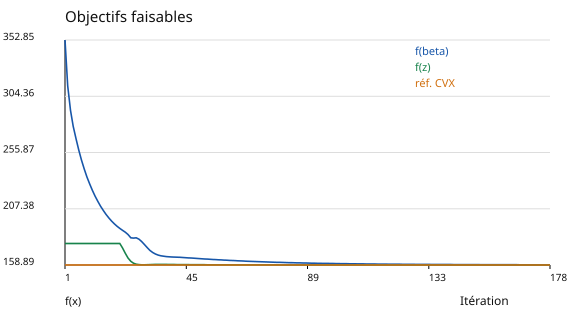

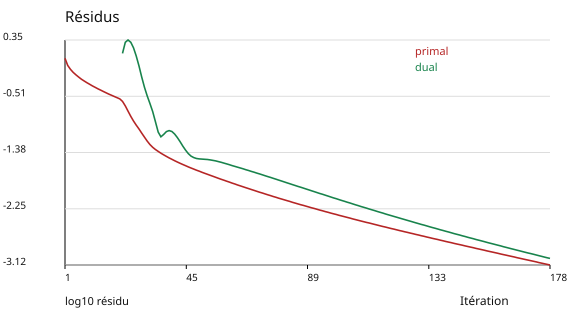

In [6]:
// Émet deux panneaux SVG opaques sous le MIME reconnu par GitHub.
record GraphSvg(string Value);
Formatter.Register<GraphSvg>((value, writer) => writer.Write(value.Value), "image/svg+xml");
string Plot(string title, string yLabel, (string label, double[] values, string color)[] series, bool logY = false, bool logX = false)
{
    const int width = 570, height = 310, left = 65, right = 20, top = 40, bottom = 45;
    var all = series.SelectMany(s => s.values).Where(v => double.IsFinite(v) && (!logY || v > 0)).Select(v => logY ? Math.Log10(v) : v).ToArray();
    double ymin = all.Min(), ymax = all.Max();
    if (ymax <= ymin) ymax = ymin + 1;
    int count = series.Max(s => s.values.Length);
    var svg = new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='{width}' height='{height}' viewBox='0 0 {width} {height}'><rect width='100%' height='100%' fill='white'/><g font-family='sans-serif' fill='#111'><text x='65' y='22' font-size='15'>{title}</text><text x='460' y='305' font-size='12'>Itération</text><text x='65' y='305' font-size='11'>{yLabel}</text><line x1='{left}' y1='{top}' x2='{left}' y2='{height-bottom}' stroke='black'/><line x1='{left}' y1='{height-bottom}' x2='{width-right}' y2='{height-bottom}' stroke='black'/>");
    for (int tick = 0; tick <= 4; tick++)
    {
        double value = ymin + (ymax - ymin) * tick / 4;
        double y = height - bottom - (height - top - bottom) * tick / 4.0;
        svg.Append($"<text x='3' y='{y:0.0}' font-size='10'>{value:0.##}</text><line x1='{left}' y1='{y:0.0}' x2='{width-right}' y2='{y:0.0}' stroke='#ddd'/>");
    }
    // Graduations en abscisse : réelles en linéaire, puissances de dix en logarithmique.
    if (logX)
    {
        for (int tick = 1; tick <= count; tick *= 10)
        {
            double x = left + (width-left-right) * Math.Log10(tick) / Math.Log10(Math.Max(2, count));
            svg.Append($"<line x1='{x:0.0}' y1='{height-bottom}' x2='{x:0.0}' y2='{height-bottom+4}' stroke='black'/><text x='{x:0.0}' y='{height-bottom+16}' font-size='10'>{tick}</text>");
            if (tick > count / 10) break;
        }
    }
    else
    {
        for (int tick = 0; tick <= 4; tick++)
        {
            double x = left + (width-left-right) * tick / 4.0;
            int iteration = 1 + (count-1) * tick / 4;
            svg.Append($"<line x1='{x:0.0}' y1='{height-bottom}' x2='{x:0.0}' y2='{height-bottom+4}' stroke='black'/><text x='{x:0.0}' y='{height-bottom+16}' font-size='10'>{iteration}</text>");
        }
    }
    int legend = 0;
    foreach (var item in series)
    {
        var points = new StringBuilder();
        for (int i = 0; i < item.values.Length; i++)
        {
            if (!double.IsFinite(item.values[i]) || (logY && item.values[i] <= 0))
            {
                if (points.Length > 0)
                {
                    svg.Append($"<polyline fill='none' stroke='{item.color}' stroke-width='1.6' points='{points}'/>");
                    points.Clear();
                }
                continue;
            }
            double value = logY ? Math.Log10(item.values[i]) : item.values[i];
            double position = logX ? Math.Log10(i + 1) / Math.Log10(Math.Max(2, count)) : i / (double)Math.Max(1, count-1);
            double px = left + (width-left-right) * position;
            double py = height-bottom - (height-top-bottom) * (value-ymin)/(ymax-ymin);
            points.Append($"{px:0.0},{py:0.0} ");
        }
        svg.Append($"<polyline fill='none' stroke='{item.color}' stroke-width='1.6' points='{points}'/><text x='{width-155}' y='{55+legend*16}' fill='{item.color}' font-size='11'>{item.label}</text>");
        legend++;
    }
    svg.Append("</g></svg>");
    return svg.ToString();
}
display(new GraphSvg(Plot("Objectifs faisables", "f(x)", new[]{("f(beta)",admm.ObjectiveBeta,"#1756a9"),("f(z)",admm.ObjectiveZ,"#18834c"),("réf. CVX",Enumerable.Repeat(optimum,admm.Primal.Length).ToArray(),"#d07010")})), "image/svg+xml");
display(new GraphSvg(Plot("Résidus", "log10 résidu", new[]{("primal",admm.Primal,"#b52525"),("dual",admm.Dual,"#18834c")},true)), "image/svg+xml");

### Exercice 2 — Quasi-colinéarité

Sur un design `80×10`, construire la deuxième colonne comme la première plus `0,001×bruit`, choisir λ=0,5 puis exécuter `ρ={0,01, 0,1, 1, 10}`. Relever supports, résidus et itérations et comparer vitesse/équilibre. Une quasi-colinéarité non exacte peut dégrader le conditionnement et rendre les supports sensibles, mais ne prouve pas à elle seule la non-unicité. Le garde vérifie les données et champs calculables sur deux graines ; l'interprétation reste humaine.

In [7]:
(Matrix<double> design, Vector<double> target, AdmmResult[] results) ExerciceColinearite(int seed)
{
    // TODO : construire le problème 80×10 et les quatre trajectoires pour cette graine.
    return (null, null, null);
}
var answers=new[]{ExerciceColinearite(7),ExerciceColinearite(42)};
if(answers.All(a=>a.design==null && a.target==null && a.results==null))
{
    Console.WriteLine("Exercice 2 à compléter.");
}
else if(answers.Any(a=>a.design==null || a.target==null || a.results==null))
{
    Console.WriteLine("Exercice 2 : à revoir");
}
else
{
    var rhos=new[]{.01,.1,1.0,10.0};
    bool ok=true;
    foreach(var answer in answers)
    {
        bool valid=answer.design.RowCount==80 && answer.design.ColumnCount==10 && answer.target.Count==80 &&
                   answer.results.Length==rhos.Length && answer.design.Enumerate().All(double.IsFinite) && answer.target.All(double.IsFinite);
        if(valid)
        {
            double norm=answer.design.Column(0).L2Norm();
            double ratio=norm>0 ? (answer.design.Column(1)-answer.design.Column(0)).L2Norm()/norm : double.PositiveInfinity;
            valid=ratio>0 && ratio<.01;
        }
        for(int i=0;valid && i<rhos.Length;i++)
            valid=ResultatCoherent(answer.results[i],Admm(answer.design,answer.target,.5,rhos[i],500));
        ok=ok && valid;
    }
    if(ok) ok=(answers[0].design-answers[1].design).FrobeniusNorm()>1e-9;
    Console.WriteLine(ok ? "Exercice 2 : calculs corrects ; examiner les supports" : "Exercice 2 : à revoir");
}

Exercice 2 à compléter.


## 5. Balayer ρ

On conserve les sept valeurs `{0,5 ; 1 ; 5 ; 20 ; 50 ; 100 ; 500}` et 500 itérations maximum. Un statut `converged=False` signifie que les deux tests n'ont pas été satisfaits dans le budget ; la cible du problème n'a pas changé. Un statut vrai est possible à la dernière itération.

Sur ce tirage, les valeurs 0,5, 1 et 5 ne passent pas les tests en 500 itérations ; 20, 50, 100 et 500 donnent respectivement 178, 74, 40 et 90 itérations dans les sorties. À 0,5, z reste nul et le résidu dual vaut zéro ; le ratio ≈66 correspond à ρ=1. Ces observations dépendent du problème et de ses tolérances.

Une heuristique peut augmenter ρ quand le primal domine largement et le diminuer quand le dual domine ; ce balayage utilise au contraire un ρ **fixe** par résolution. L'équilibrage n'est pas un certificat de conditionnement ou de vitesse optimale. Lorsque ρ augmente, le seuil λ/ρ diminue et `XᵀX+ρI` est mieux conditionnée ; le résidu dual contient ρ mais aussi une différence d'itérés qui change elle-même, donc il ne varie pas proportionnellement entre runs.

Une règle adaptative souvent étudiée utilise `μ=10` et `τ=2` : doubler ρ si `r_p>μ r_d`, le diviser par deux si `r_d>μ r_p`, sinon le conserver. Elle n'est pas exécutée par le balayage fixe ci-dessous. Si l'on change ρ en cours de route avec la variable duale échelonnée `u`, il faut aussi la rééchelonner par `ρ_ancien/ρ_nouveau` pour conserver la variable duale non échelonnée cohérente.

In [8]:
foreach (double rho in new[]{0.5, 1.0, 5.0, 20.0, 50.0, 100.0, 500.0})
{
    var result = Admm(x, y, lambda, rho, 500);
    double rp = result.Primal.Last();
    double rd = result.Dual.Last();
    Console.WriteLine($"ρ={rho,6:F1}, it={result.Primal.Length,3}, convergé={result.Converged,-5}, écart={(result.Z-cvx).L2Norm():E3}, f(z)={result.ObjectiveZ.Last():F4}, support={result.Z.Count(v => Math.Abs(v)>1e-6)}, rp={rp:E3}, rd={rd:E3}, ratio={(rd>0 ? rp/rd : double.PositiveInfinity):F2}");
}

ρ=   0.5, it=500, convergé=False, écart=6.567E-001, f(z)=177.4140, support=0, rp=4.022E-001, rd=0.000E+000, ratio=Infinity


ρ=   1.0, it=500, convergé=False, écart=1.817E-001, f(z)=160.3060, support=2, rp=1.193E-001, rd=1.794E-003, ratio=66.49


ρ=   5.0, it=500, convergé=False, écart=7.013E-003, f(z)=158.8935, support=2, rp=2.348E-003, rd=2.269E-004, ratio=10.35


ρ=  20.0, it=178, convergé=True , écart=2.078E-003, f(z)=158.8907, support=2, rp=7.613E-004, rd=9.614E-004, ratio=0.79


ρ=  50.0, it= 74, convergé=True , écart=2.015E-003, f(z)=158.8907, support=2, rp=7.625E-004, rd=5.803E-003, ratio=0.13


ρ= 100.0, it= 40, convergé=True , écart=1.924E-003, f(z)=158.8906, support=2, rp=7.490E-004, rd=1.027E-002, ratio=0.07


ρ= 500.0, it= 90, convergé=True , écart=1.700E-004, f(z)=158.8905, support=2, rp=5.282E-005, rd=2.062E-002, ratio=0.00


### Exercice 3 — ADMM ridge

Pour `min ½‖Xβ−y‖²+λ‖z‖²₂` sous `β=z`, conserver β et u mais remplacer le proximal L1 par `z=ρ/(ρ+2λ)·(β+u)`. Ce proximal est une homothétie sans zone morte : une entrée non nulle ne s'annule pas, tandis qu'une entrée déjà nulle reste nulle. Comparer le résultat à `(XᵀX+2λI)⁻¹Xᵀy` sur plusieurs matrices et paramètres. Le garde de résultat ne certifie pas que l'étudiant a effectivement utilisé ADMM.

In [9]:
Vector<double> ExerciceRidge(Matrix<double> matrix, Vector<double> target, double lam, double rho)
{
    // TODO : implémenter ADMM avec proximal ridge, puis renvoyer z.
    return null;
}
var fixturesRidge=new[]
{
    (Mat.DenseOfArray(new double[,] {{2,0},{0,1}}),V.DenseOfArray(new[]{4.0,-3.0}),.5,2.0),
    (Mat.DenseOfArray(new double[,] {{1,1},{1,0},{0,2}}),V.DenseOfArray(new[]{2.0,1.0,-1.0}),.3,.7),
    (Mat.DenseOfArray(new double[,] {{2,-1},{.5,1},{-1,2}}),V.DenseOfArray(new[]{-1.0,2.0,.5}),1.2,4.0)
};
var answersRidge=fixturesRidge.Select(f=>ExerciceRidge(f.Item1,f.Item2,f.Item3,f.Item4)).ToArray();
if(answersRidge.All(a=>a==null))
{
    Console.WriteLine("Exercice 3 à compléter.");
}
else if(answersRidge.Any(a=>a==null))
{
    Console.WriteLine("Exercice 3 : à revoir");
}
else
{
    bool ok=true;
    for(int i=0;i<fixturesRidge.Length;i++)
    {
        var (matrix,target,lam,rho)=fixturesRidge[i];
        // Résoudre l'équation ridge indépendamment de l'ADMM ; ce test ne prouve pas la méthode utilisée.
        var at=matrix.Transpose();
        var expected=(at*matrix+2*lam*Mat.DenseIdentity(matrix.ColumnCount)).Cholesky().Solve(at*target);
        var value=answersRidge[i];
        ok=ok && value.Count==expected.Count && value.All(double.IsFinite);
        if(ok) ok=(value-expected).L2Norm()<1e-3;
    }
    Console.WriteLine(ok ? "Exercice 3 : résultat cohérent ; la méthode reste à examiner" : "Exercice 3 : à revoir");
}

Exercice 3 à compléter.


## 6. Synthèse

| Élément | Rôle | Observation sur ce tirage |
|---|---|---|
| β | sous-problème quadratique | 48 composantes au-dessus de 10⁻⁶ dans la sortie |
| z | proximal L1, support évalué | deux composantes retenues |
| u, `r_p`, `r_d` | consensus et stationnarité approchés | deux tests de tolérance |
| ρ | paramètre de trajectoire | les sept valeurs explorées ont des coûts différents |
| λ et `ρ_corr` | problème et population des données | fixés pendant le balayage |

Les sorties comparent les quatre méthodes : sur cette instance, z, la descente de coordonnées et sklearn ont deux supports, zéro faux positif, rappel 40 %, précision 100 % et F1 proche de 57 %. Les écarts à la référence CVXPY sont calculés, pas des certificats exacts. La lecture des normes et résidus éclaire pourquoi β et z diffèrent à arrêt fini. Les temps indiquent le coût mesuré dans chaque environnement ; les mesures Python excluent les conversions et l'initialisation du pont, et les chronomètres C# encadrent leurs solveurs natifs.


Le rappel observé de 2/5 résulte ici du problème résolu au λ choisi : les méthodes comparées retrouvent le même petit support à leurs tolérances. Cela ne prouve ni qu'un autre algorithme retrouverait les cinq composantes avec ce λ, ni qu'un changement de λ les retrouverait nécessairement. LassoCV pourrait choisir un λ selon un protocole de validation, mais ce choix n'est pas exécuté dans cette expérience.

## À retenir

1. ADMM alterne β, z et u et utilise deux résidus avec deux tolérances.
2. `ρ_corr` caractérise la covariance de population ; `ρ` règle la trajectoire. `λ` et `α=λ/n` sont les deux unités des mêmes objectifs.
3. Le rang et le conditionnement sont mesurés. La convexité ne garantit pas l'unicité sans hypothèse supplémentaire.
4. Le balayage compare des runs distincts : l'équilibrage est une heuristique, le facteur ρ du résidu dual n'implique pas une proportionnalité inter-runs.
5. CLARABEL/SCS fournissent une référence numérique. La proximité d'objectifs, de supports et de temps s'interprète avec les critères d'arrêt et le seuil de comptage.

## Vérifiez votre compréhension

**1. Pourquoi le support est-il lu sur z ?**

<details><summary>Réponse</summary>Le proximal L1 agit sur z. β est issu d'un système quadratique et peut être plus dense à tolérance finie ; 48 composantes au-dessus du seuil sont observées ici, sans règle universelle.</details>

**2. Que mesurent les deux résidus ?**

<details><summary>Réponse</summary>`‖β−z‖` mesure le consensus et `ρ‖z−z_prev‖` la stationnarité approchée ; chacun a sa propre tolérance.</details>

**3. ρ=1 ne converge pas dans 500 itérations, tandis que ρ=100 s’arrête en 40 : que change ρ ?**

<details><summary>Réponse</summary>Augmenter ρ diminue λ/ρ et améliore le conditionnement de `XᵀX+ρI`, mais change aussi les itérés ; le meilleur temps dépend du problème et du critère.</details>

**4. Pourquoi z ADMM est-il à environ 2,08·10⁻³ de CVXPY quand la descente de coordonnées est à environ 1,00·10⁻⁷ ?**

<details><summary>Réponse</summary>Les méthodes ont des critères et tolérances différents. CVXPY donne une référence numérique ; un petit écart ne prouve pas une identité exacte des vecteurs.</details>

## Pour aller plus loin

La source Python cite les repères bibliographiques du cours, dont Boyd et collaborateurs (2011) pour ADMM ; [2.11e](2.11e-CVXPY-Optimisation.ipynb) examine CVXPY et [2.11f](2.11f-Comparaison-Optimisation-Convexe.ipynb) compare les méthodes.



### Références et voisins

- Boyd, S., Parikh, N., Chu, E., Peleato, B. & Eckstein, J. (2011). *Distributed Optimization and Statistical Learning via the Alternating Direction Method of Multipliers*, Foundations and Trends in Machine Learning, 3(1), 1–122 : §3.3.1 (résidus), §3.4.1 (ajustement de ρ), §6.4 (Lasso).
- Les carnets [2.7b SMO](2.7b-SMO-From-Scratch.ipynb) et [2.7c LIBSVM](2.7c-SVM-SOTA-Comparison.ipynb) suivent la chaîne SVM parallèle ; [2.11e](2.11e-CVXPY-Optimisation.ipynb) et [2.11f](2.11f-Comparaison-Optimisation-Convexe.ipynb) poursuivent la chaîne Lasso.

Références reprises du carnet Python versionné ; les hypothèses des résultats externes ne sont pas présumées vérifiées sur ce tirage.